In [1]:
import pandas as pd
import numpy as np

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
movies = pd.read_csv(
    "../data/processed/movies_cleaned.csv"
)

print(movies.shape)
movies.head()

(4803, 3)


,movie_id,title,tags
0,19995,Avatar,"in the 22nd century, a paraplegic marine is di..."
1,285,Pirates of the Caribbean: At World's End,"captain barbossa, long believed to be dead, ha..."
2,206647,Spectre,a cryptic message from bond’s past sends him o...
3,49026,The Dark Knight Rises,following the death of district attorney harve...
4,49529,John Carter,"john carter is a war-weary, former military ca..."


In [3]:
print(movies.isnull().sum())
print(movies.duplicated(subset=["movie_id"]).sum())

movie_id    0
title       0
tags        0
dtype: int64
0


In [4]:
cv = CountVectorizer(
    max_features=5000,
    stop_words="english"
)

vectors = cv.fit_transform(movies["tags"].fillna(""))

In [5]:
print("Vector shape:", vectors.shape)
print("Vocabulary size:", len(cv.vocabulary_))

Vector shape: (4803, 5000)
Vocabulary size: 5000


In [6]:
similarity = cosine_similarity(
    vectors[0],
    vectors
)

print(similarity.shape)

(1, 4803)


In [7]:
def recommend(movie_name, top_n=10):

    # Find the movie index
    movie_indices = movies[
        movies["title"].str.casefold() == movie_name.casefold()
    ].index

    if len(movie_indices) == 0:
        return f"Movie '{movie_name}' not found!"

    movie_index = movie_indices[0]

    # Calculate similarity with all movies
    similarity_scores = cosine_similarity(
        vectors[movie_index],
        vectors
    ).flatten()

    # Get movie indices sorted by similarity
    similar_movies = sorted(
        enumerate(similarity_scores),
        key=lambda x: x[1],
        reverse=True
    )

    # Exclude the selected movie itself
    similar_movies = [
        item for item in similar_movies
        if item[0] != movie_index
    ]

    # Return top N recommendations
    recommendations = []

    for index, score in similar_movies[:top_n]:

        recommendations.append({
            "title": movies.iloc[index]["title"],
            "similarity": round(float(score), 4)
        })

    return recommendations

In [10]:
recommend("The Dark Knight")

[{'title': 'The Dark Knight Rises', 'similarity': 0.4066},
 {'title': 'Batman Begins', 'similarity': 0.3756},
 {'title': 'Batman Returns', 'similarity': 0.314},
 {'title': 'Batman Forever', 'similarity': 0.2835},
 {'title': 'Batman & Robin', 'similarity': 0.259},
 {'title': "Amidst the Devil's Wings", 'similarity': 0.252},
 {'title': 'Batman v Superman: Dawn of Justice', 'similarity': 0.2498},
 {'title': 'Batman', 'similarity': 0.2381},
 {'title': 'Batman: The Dark Knight Returns, Part 2', 'similarity': 0.2381},
 {'title': "Gangster's Paradise: Jerusalema", 'similarity': 0.2224}]

In [11]:
recommend("Avatar")

recommend("Iron Man")

recommend("Interstellar")

recommend("Titanic")

[{'title': 'Captain Phillips', 'similarity': 0.287},
 {'title': 'The Notebook', 'similarity': 0.2655},
 {'title': 'In the Heart of the Sea', 'similarity': 0.2583},
 {'title': 'Ghost Ship', 'similarity': 0.2557},
 {'title': 'Poseidon', 'similarity': 0.2396},
 {'title': 'Romance & Cigarettes', 'similarity': 0.2327},
 {'title': 'The Bounty', 'similarity': 0.2301},
 {'title': 'Love Letters', 'similarity': 0.2199},
 {'title': 'Triangle', 'similarity': 0.2196},
 {'title': 'Pirates of the Caribbean: On Stranger Tides',
  'similarity': 0.2185}]

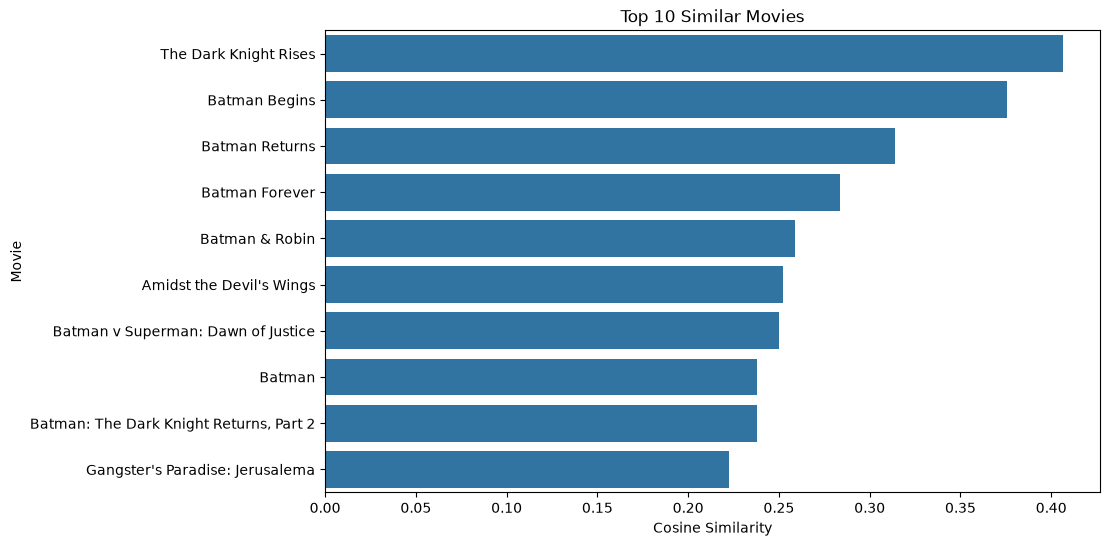

In [12]:
result = recommend("The Dark Knight", top_n=10)

recommendation_df = pd.DataFrame(result)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=recommendation_df,
    x="similarity",
    y="title"
)

plt.title("Top 10 Similar Movies")
plt.xlabel("Cosine Similarity")
plt.ylabel("Movie")

plt.show()

In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

tfidf_vectors = tfidf.fit_transform(
    movies["tags"].fillna("")
)

print(tfidf_vectors.shape)

(4803, 5000)


In [14]:
tfidf_similarity = cosine_similarity(
    tfidf_vectors[0],
    tfidf_vectors
).flatten()

print(
    sorted(
        enumerate(tfidf_similarity),
        key=lambda x: x[1],
        reverse=True
    )[:10]
)

[(0, np.float64(1.0)), (3724, np.float64(0.20354233646724276)), (582, np.float64(0.19410894501161607)), (3604, np.float64(0.1839084762989157)), (47, np.float64(0.17110990997739733)), (539, np.float64(0.1653203829185545)), (2403, np.float64(0.16265507681511127)), (942, np.float64(0.16261499438741342)), (260, np.float64(0.16024159894455675)), (557, np.float64(0.15997835684912828))]


In [15]:
# Existing movie
print(recommend("The Dark Knight"))

# Movie that does not exist
print(recommend("Random Movie XYZ"))

# Different capitalization
print(recommend("the dark knight"))

# Different number of recommendations
print(recommend("Avatar", top_n=5))

[{'title': 'The Dark Knight Rises', 'similarity': 0.4066}, {'title': 'Batman Begins', 'similarity': 0.3756}, {'title': 'Batman Returns', 'similarity': 0.314}, {'title': 'Batman Forever', 'similarity': 0.2835}, {'title': 'Batman & Robin', 'similarity': 0.259}, {'title': "Amidst the Devil's Wings", 'similarity': 0.252}, {'title': 'Batman v Superman: Dawn of Justice', 'similarity': 0.2498}, {'title': 'Batman', 'similarity': 0.2381}, {'title': 'Batman: The Dark Knight Returns, Part 2', 'similarity': 0.2381}, {'title': "Gangster's Paradise: Jerusalema", 'similarity': 0.2224}]
Movie 'Random Movie XYZ' not found!
[{'title': 'The Dark Knight Rises', 'similarity': 0.4066}, {'title': 'Batman Begins', 'similarity': 0.3756}, {'title': 'Batman Returns', 'similarity': 0.314}, {'title': 'Batman Forever', 'similarity': 0.2835}, {'title': 'Batman & Robin', 'similarity': 0.259}, {'title': "Amidst the Devil's Wings", 'similarity': 0.252}, {'title': 'Batman v Superman: Dawn of Justice', 'similarity': 0.24

In [16]:
vectors.shape

(4803, 5000)

In [17]:
recommend("The Dark Knight")

[{'title': 'The Dark Knight Rises', 'similarity': 0.4066},
 {'title': 'Batman Begins', 'similarity': 0.3756},
 {'title': 'Batman Returns', 'similarity': 0.314},
 {'title': 'Batman Forever', 'similarity': 0.2835},
 {'title': 'Batman & Robin', 'similarity': 0.259},
 {'title': "Amidst the Devil's Wings", 'similarity': 0.252},
 {'title': 'Batman v Superman: Dawn of Justice', 'similarity': 0.2498},
 {'title': 'Batman', 'similarity': 0.2381},
 {'title': 'Batman: The Dark Knight Returns, Part 2', 'similarity': 0.2381},
 {'title': "Gangster's Paradise: Jerusalema", 'similarity': 0.2224}]

In [18]:
recommend("Interstellar")

[{'title': 'Silent Running', 'similarity': 0.2387},
 {'title': 'Space Pirate Captain Harlock', 'similarity': 0.2309},
 {'title': 'The Martian', 'similarity': 0.2273},
 {'title': 'Apollo 13', 'similarity': 0.2247},
 {'title': 'Space Cowboys', 'similarity': 0.2176},
 {'title': 'Gravity', 'similarity': 0.2083},
 {'title': 'Solaris', 'similarity': 0.2076},
 {'title': 'Lost in Space', 'similarity': 0.2},
 {'title': "Ender's Game", 'similarity': 0.1938},
 {'title': 'The Right Stuff', 'similarity': 0.1935}]

In [19]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

tfidf_vectors = tfidf.fit_transform(movies["tags"].fillna(""))

def recommend_tfidf(movie_name, top_n=10):

    indices = movies[
        movies["title"].str.casefold() == movie_name.casefold()
    ].index

    if len(indices) == 0:
        return "Movie not found!"

    movie_index = indices[0]

    scores = cosine_similarity(
        tfidf_vectors[movie_index],
        tfidf_vectors
    ).flatten()

    similar_movies = sorted(
        enumerate(scores),
        key=lambda x: x[1],
        reverse=True
    )

    return [
        {
            "title": movies.iloc[i]["title"],
            "similarity": round(float(score), 4)
        }
        for i, score in similar_movies
        if i != movie_index
    ][:top_n]

In [21]:
print("THE DARK KNIGHT")
display(pd.DataFrame(
    recommend_tfidf("The Dark Knight")
))

print("INTERSTELLAR")
display(pd.DataFrame(
    recommend_tfidf("Interstellar")
))

THE DARK KNIGHT


,title,similarity
0,The Dark Knight Rises,0.4325
1,Batman Returns,0.3749
2,Batman Begins,0.3308
3,"Batman: The Dark Knight Returns, Part 2",0.2988
4,Batman Forever,0.2979
5,Batman v Superman: Dawn of Justice,0.2663
6,Batman & Robin,0.2161
7,Batman,0.1891
8,The Lego Movie,0.1457
9,Superman,0.1390


INTERSTELLAR


,title,similarity
0,Apollo 13,0.2139
1,Space Pirate Captain Harlock,0.2035
2,Space Cowboys,0.2005
3,The Martian,0.1950
4,Armageddon,0.1663
5,Silent Running,0.1647
6,The Right Stuff,0.1630
7,Escape from Planet Earth,0.1603
8,Deep Impact,0.1551
9,Gravity,0.1544
